# PDF de-identification with `Visual NLP`

`PdfDeidentifier` replaces the PHI detected by a Spark NLP de-identification pipeline **directly in the text layer of a digital PDF**.
The obfuscated values are written with the original font, size, color and position, so the output PDF looks like the original
but holds fake values. It stays a real text PDF: searchable and copyable.

Pipeline: `PdfToText` → NLP stages (NER + `DeIdentification` in obfuscation mode) → `PdfDeidentifier`.

* `PdfToText` needs `setStoreSplittedPdf(True)` so that the PDF of each page is kept in the `content` column.
* `DeIdentification` needs `setReturnEntityMappings(True)`. Its mappings column (`aux`) holds, for every entity, the original text (`metadata.originalChunk`) and the fake value (`result`).
* `PdfDeidentifier` replaces the text page by page and merges the pages back into one PDF per document.

## Setup

In [4]:
from sparkocr import start

spark = start(jar_path=spark_ocr_jar_path, nlp_version=nlp_version,
              nlp_internal=nlp_version, nlp_secret=nlp_secret)
spark

Spark version: 3.5.1
Spark NLP version: 7.0.0-rc4
Spark NLP for Healthcare version: 7.0.0
Spark OCR version: 7.0.1rc2



In [5]:
from sparkocr.transformers import *
from sparkocr.utils import display_images_horizontal

from sparknlp.base import DocumentAssembler
from sparknlp.annotator import SentenceDetector, Tokenizer, WordEmbeddingsModel
from sparknlp_jsl.annotator import MedicalNerModel, NerConverterInternal, DeIdentification

from pyspark.ml import Pipeline, PipelineModel
import pyspark.sql.functions as F

## Input PDF

In [6]:
pdf_path = "../../workshop/jupyter/deid-and-obfuscation/source_pdfs/Easy/PDF_Deid_Deidentification_0.pdf"
input_df = spark.read.format("binaryFile").load(pdf_path)

## Pipeline

In [7]:
pdf_to_text = PdfToText() \
    .setInputCol("content") \
    .setOutputCol("text") \
    .setSplitPage(True) \
    .setStoreSplittedPdf(True)  # keep the PDF of each page in `content`

document_assembler = DocumentAssembler() \
    .setInputCol("text") \
    .setOutputCol("document")

sentence_detector = SentenceDetector() \
    .setInputCols(["document"]) \
    .setOutputCol("sentence")

tokenizer = Tokenizer() \
    .setInputCols(["sentence"]) \
    .setOutputCol("token")

word_embeddings = WordEmbeddingsModel.pretrained("embeddings_clinical", "en", "clinical/models") \
    .setInputCols(["sentence", "token"]) \
    .setOutputCol("embeddings")

ner = MedicalNerModel.pretrained("ner_deid_sd", "en", "clinical/models") \
    .setInputCols(["sentence", "token", "embeddings"]) \
    .setOutputCol("ner")

ner_converter = NerConverterInternal() \
    .setInputCols(["sentence", "token", "ner"]) \
    .setOutputCol("ner_chunk")

deidentification = DeIdentification() \
    .setInputCols(["sentence", "token", "ner_chunk"]) \
    .setOutputCol("obfuscated") \
    .setMode("obfuscate") \
    .setObfuscateDate(True) \
    .setKeepTextSizeForObfuscation(True) \
    .setFakerLengthOffset(2) \
    .setConsistentObfuscation(True) \
    .setGroupByCol("path") \
    .setSeed(40) \
    .setReturnEntityMappings(True) \
    .setMappingsColumn("aux")

pdf_deidentifier = PdfDeidentifier() \
    .setInputCol("content") \
    .setInputMappingCol("aux") \
    .setOutputCol("pdf")

pipeline = Pipeline(stages=[
    pdf_to_text,
    document_assembler,
    sentence_detector,
    tokenizer,
    word_embeddings,
    ner,
    ner_converter,
    deidentification,
    pdf_deidentifier,
])

embeddings_clinical download started this may take some time.
Approximate size to download 1.6 GB
[OK!]
ner_deid_sd download started this may take some time.
Approximate size to download 14 MB
[OK!]


[ / ]

[ — ]

[ \ ]

[OK!]


ner_deid_sd download started this may take some time.


Approximate size to download 14 MB
[ | ]

[ / ]

[OK!]

## Run

In [8]:
model = pipeline.fit(input_df)
result = model.transform(input_df).cache()
result.select("path", "exception").show(truncate=False)

+----------------------------------------------------------------------------------------------------------------+---------+
|path                                                                                                            |exception|
+----------------------------------------------------------------------------------------------------------------+---------+
|file:/home/jose/spark-ocr/workshop/jupyter/deid-and-obfuscation/source_pdfs/Easy/PDF_Deid_Deidentification_0.pdf|         |
+----------------------------------------------------------------------------------------------------------------+---------+



Entities detected and their replacements. Here we run the pipeline without its last stage, to look at the per page mappings
that `PdfDeidentifier` consumes.

In [9]:
pages = PipelineModel(stages=model.stages[:-1]).transform(input_df)

pages.select("pagenum", F.explode("aux").alias("m")) \
    .select("pagenum",
            F.col("m.metadata.entity").alias("entity"),
            F.col("m.metadata.originalChunk").alias("original"),
            F.col("m.result").alias("replacement")) \
    .orderBy("pagenum") \
    .show(50, truncate=False)

+-------+--------+-------------------------------------------------------------------------------------+----------------------------------------+
|pagenum|entity  |original                                                                             |replacement                             |
+-------+--------+-------------------------------------------------------------------------------------+----------------------------------------+
|0      |LOCATION|Trauma\nCenter\nKimberly Lawrence     24/05/1977\nSierra Valley Medical Institute INC|24 Joliet St                            |
|0      |NAME    |Kimberly Lawrence                                                                    |Porfirio Greening                       |
|0      |DATE    |24/05/1977                                                                           |29/06/1977                              |
|0      |NAME    |Kimberly\nLawrence                                                                   |Porfirio Greening   

## Original vs de-identified

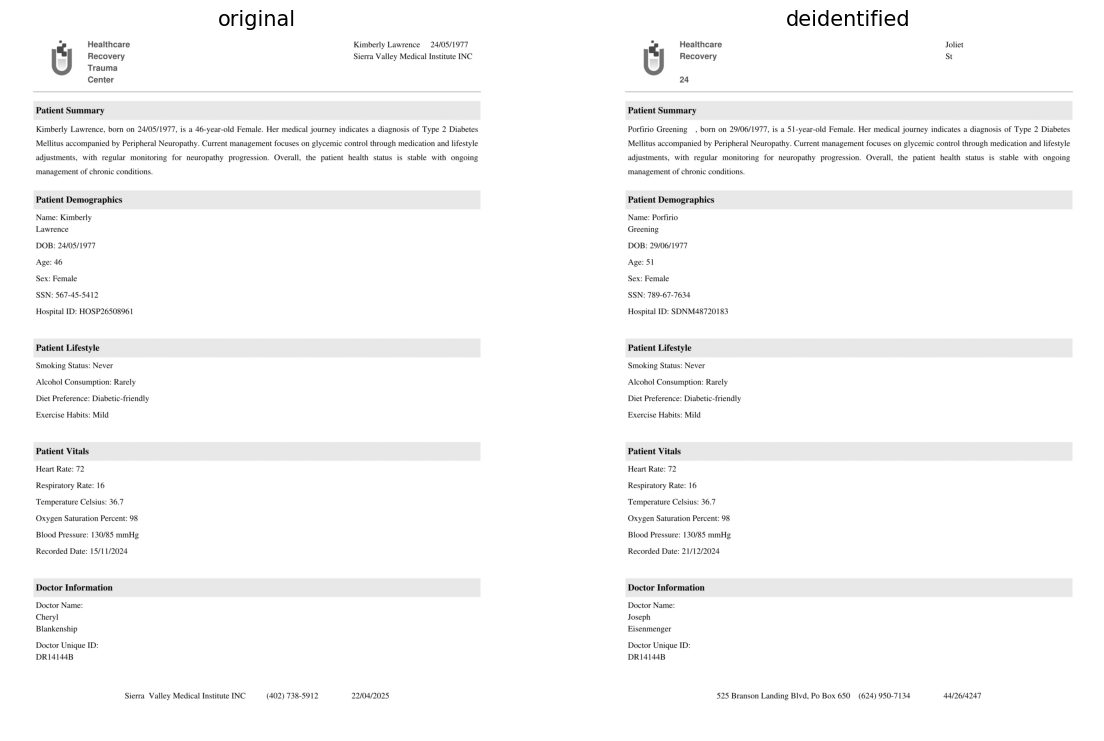

In [10]:
original_pages = PdfToImage().setInputCol("content").setOutputCol("original") \
    .transform(input_df).select("path", "pagenum", "original")
deid_pages = PdfToImage().setInputCol("pdf").setOutputCol("deidentified") \
    .transform(result.select("path", "pdf")).select("path", "pagenum", "deidentified")

display_images_horizontal(original_pages.join(deid_pages, ["path", "pagenum"]).orderBy("pagenum"),
                          "original, deidentified", limit=1, show_meta=False)

The output is still a text PDF: the originals are gone from its text layer and the fake values are there.

In [11]:
deid_text = PdfToText().setInputCol("pdf").setOutputCol("text").setSplitPage(False) \
    .transform(result.select("path", "pdf")).select("text").first().text

mappings = pages.select(F.explode("aux").alias("m")) \
    .select(F.col("m.metadata.originalChunk").alias("original"), F.col("m.result").alias("replacement")) \
    .distinct().collect()
for m in mappings[:10]:
    print(f"{m.original!r:45} in output: {m.original in deid_text!s:5}   {m.replacement!r:40} in output: {m.replacement in deid_text}")

'Trauma\nCenter\nKimberly Lawrence     24/05/1977\nSierra Valley Medical Institute INC' in output: False   '24 Joliet St'                           in output: False
'02/08/2024'                                  in output: False   '07/09/2024'                             in output: True
'Cheryl\nBlankenship'                         in output: False   'Joseph Eisenmenger'                     in output: False
'46'                                          in output: False   '51'                                     in output: True
'Sierra Valley Medical Institute INC'         in output: False   '525 Branson Landing Blvd, Po Box 650'   in output: True
'15/05/2024'                                  in output: False   '20/06/2024'                             in output: True
'HOSP26508961'                                in output: False   'SDNM48720183'                           in output: True
'05/08/2023'                                  in output: False   '10/09/2023'                         

## Save

In [12]:
os.makedirs("output", exist_ok=True)
for row in result.select("path", "pdf").collect():
    out = os.path.join("output", os.path.basename(row.path).replace(".pdf", "_deid.pdf"))
    with open(out, "wb") as f:
        f.write(row.pdf)
    print("Saved", out)

Saved output/PDF_Deid_Deidentification_0_deid.pdf
